# Estimating categories

Many spatial variables are categories, not amounts. A geological map gives each place a rock type, a
land-cover map a class of vegetation or use, a soil survey a soil type. Categorical ESI estimates such
a variable with the same ensemble of partitions as the continuous one, a classifier taking the place of
the decoder in each cell. Here we estimate the lithology of a real geological map whose whole extent we
know, compare classifiers, read the probability of each category from the members, and find where the
map is likely to be wrong. Two further data sets, samples along boreholes of a copper deposit, then show
an amount estimated within categories and categories in three dimensions.

## Learning goals

- How categorical ESI estimates a category, a classifier in each cell, a vote over the partitions.
- How the classifiers compare, among themselves and against a single classifier fitted on all the data.
- How to read the probability of each category, and the disagreement of the members, from one result.
- How an ordered variable, such as a geological era, is aggregated.
- How an amount within categories, and categories in three dimensions, are estimated.

*What does an ensemble add to the estimate of a category?*

## The idea

In each partition, the cell that holds a location trains a classifier on its own data and predicts the
category there. The members of the location are then categories, one per partition. Their **vote**
gives the estimate, the category most members name. Their **shares** give the probability of each category. The share of members that disagree with the vote, the *disagreement*, says how sure the ensemble is.

The classifier plays the part of the decoder. `"knn"` takes the majority of the nearest data of the
cell. `"knn_pca"` does the same in a frame stretched along the directions in which the categories form
bands, a frame it fits per cell. `"svm"`, `"rf"` and `"dt"` train a support-vector machine, a random
forest or a decision tree, and `"scikit-learn"` takes any scikit-learn classifier. The theory page
[Categorical estimation](https://spatialize.readthedocs.io/en/latest/theory/categorical.html) gives the
details, and the tutorial on aggregating categorical ensembles compares the ways of turning the members
into one category.

## Step by step

### A geological map with a known truth

The data come from the State Geologic Map Compilation of the U.S. Geological Survey, near Golden,
Colorado, on a 120 × 120 grid. Each cell carries one of six lithologies and one of four geological eras.
We sample 300 cells at random and keep the whole map as the truth.

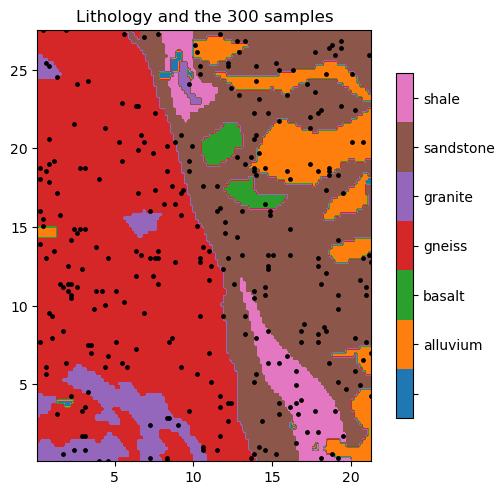

,gneiss,sandstone,alluvium,shale,granite,basalt
samples,132,109,25,18,15,1


In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

import spatialize
from spatialize.data import load_lithology_golden, load_drill_holes_andes_2D, load_drill_holes_andes_3D
from spatialize.gs.cat_esi import cat_esi_nongriddata, cat_esi_hparams_search
from spatialize.gs.esi import esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)

samples, grid, units = load_lithology_golden()
points, rocks = samples[["x", "y"]].values, samples["lithology"].values
xi, truth = grid[["x", "y"]].values, grid["lithology"].values
shape = (120, 120)                                   # the grid runs along x first, so maps are [y, x]
extent = (grid.x.min(), grid.x.max(), grid.y.min(), grid.y.max())
lithologies = sorted(set(truth))
palette = ListedColormap(plt.cm.tab10.colors[:len(lithologies)])

def category_map(labels, categories=lithologies):
    return np.array([categories.index(c) for c in labels], float).reshape(shape)

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(category_map(truth), origin="lower", extent=extent, cmap=palette,
               vmin=-0.5, vmax=len(lithologies) - 0.5)
ax.scatter(points[:, 0], points[:, 1], s=6, c="black")
cbar = fig.colorbar(im, ax=ax, ticks=range(len(lithologies)), shrink=0.8)
cbar.ax.set_yticklabels(lithologies)
ax.set_title("Lithology and the 300 samples")
plt.show()
pd.Series(rocks).value_counts().rename("samples").to_frame().T

Gneiss and sandstone dominate the samples, while basalt appears in a single sample. A category this
rare can only be estimated near its one datum, whatever the method.

### Choosing the granularity

`cat_esi_hparams_search` scores each granularity by cross-validation, here the share of held-out samples
whose category the ensemble gets right, with five folds. The classifier is `"knn_pca"`.

In [2]:
search = cat_esi_hparams_search(points, rocks, xi, classifier="knn_pca", n_partitions=[100],
                                alpha=[0.6, 0.7, 0.8, 0.9, 0.95], k=5, scoring="accuracy", seed=0)
best = search.best_result()
print(f"alpha {best['alpha']}, cross-validated accuracy {1 - best['cv_error']:.3f}")

alpha 0.7, cross-validated accuracy 0.847


### The estimated map

share of the map estimated right 0.817


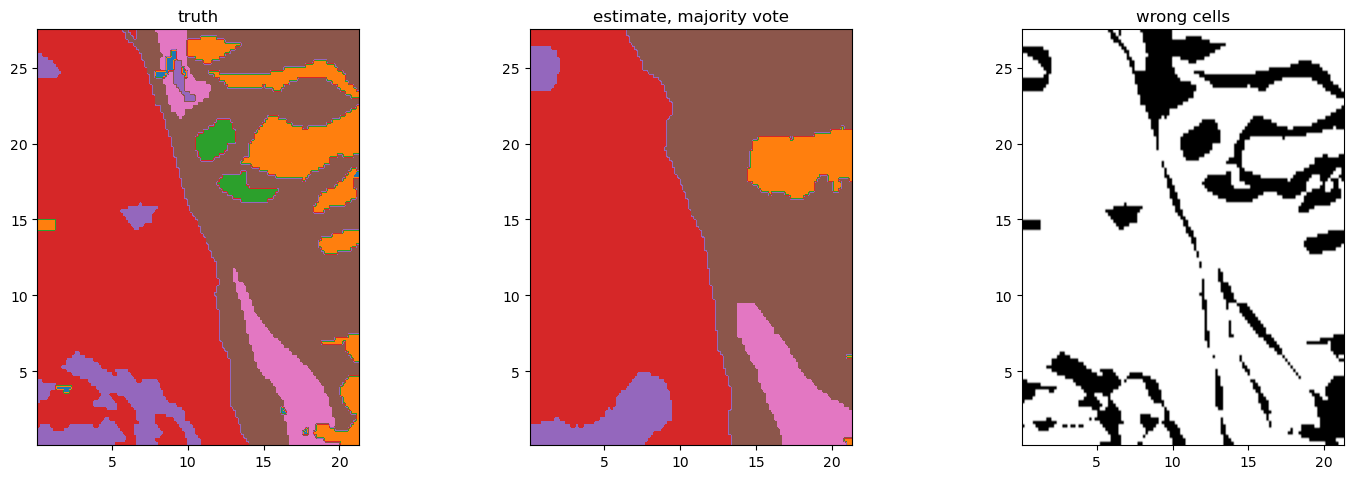

In [3]:
result = cat_esi_nongriddata(points, rocks, xi, classifier="knn_pca", n_partitions=200, alpha=best["alpha"], seed=0)
estimate = result.estimation()
wrong = estimate != truth
print(f"share of the map estimated right {1 - wrong.mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
for ax, (title, z, cmap) in zip(axes, [("truth", category_map(truth), palette),
                                      ("estimate, majority vote", category_map(estimate), palette),
                                      ("wrong cells", wrong.reshape(shape).astype(float), "Greys")]):
    ax.imshow(z, origin="lower", extent=extent, cmap=cmap,
              **({"vmin": -0.5, "vmax": len(lithologies) - 0.5} if cmap is palette else {}))
    ax.set_title(title)
plt.show()

The estimate keeps the large units and their orientation. The wrong cells gather along the contacts
between units and in the small units few samples reach.

### The classifiers

The same partitions run with each classifier, all read with the majority vote. Two classifiers fitted
once on all the data, without partitions, serve as references.

In [4]:
classifiers = {"knn": {}, "knn_pca": {}, "svm": {}, "rf": {}, "dt": {},
               "scikit-learn, 5 nearest neighbours": dict(classifier="scikit-learn",
                                                          sklearn_classifier=KNeighborsClassifier(5))}
rows, estimates = {}, {}
for name, options in classifiers.items():
    options = dict(classifier=name, **options) if "classifier" not in options else options
    start = time.perf_counter()
    r = cat_esi_nongriddata(points, rocks, xi, n_partitions=100, alpha=best["alpha"], seed=0, **options)
    estimates[f"ensemble, {name}"] = r.estimation()
    rows[f"ensemble, {name}"] = {"share right": (r.estimation() == truth).mean(),
                                 "seconds": time.perf_counter() - start}
for name, model in (("k nearest neighbours", KNeighborsClassifier(7)),
                    ("random forest", RandomForestClassifier(200, random_state=0))):
    start = time.perf_counter()
    estimates[f"one classifier, {name}"] = model.fit(points, rocks).predict(xi)
    rows[f"one classifier, {name}"] = {"share right": (estimates[f"one classifier, {name}"] == truth).mean(),
                                       "seconds": time.perf_counter() - start}
pd.DataFrame(rows).T.round(3)

,share right,seconds
"ensemble, knn",0.783,12.531
"ensemble, knn_pca",0.816,4.093
"ensemble, svm",0.770,2.766
"ensemble, rf",0.829,18.382
"ensemble, dt",0.797,0.309
"ensemble, scikit-learn, 5 nearest neighbours",0.783,12.355
"one classifier, k nearest neighbours",0.807,0.128
"one classifier, random forest",0.825,0.101


The random forest in each cell gets 83 % of the map right, closely followed by `knn_pca` at 82 %. The
decision tree reaches 80 %, while `knn`, the support-vector machine and the five nearest neighbours of
scikit-learn stay between 77 % and 78 %. Fitted once on all the data, without partitions, the nearest
neighbours reach 81 % and the random forest 83 %. On this map the partitions add little accuracy. They add the probabilities and the disagreement that follow, which no single classifier gives.
`knn_pca` takes a quarter of the random forest's time for nearly the same share, so we keep it.

### Eight maps of the same data

The maps behind the table show more than their shares. Each draws the units a little differently, and
none of them sees the small units that no sample reached.

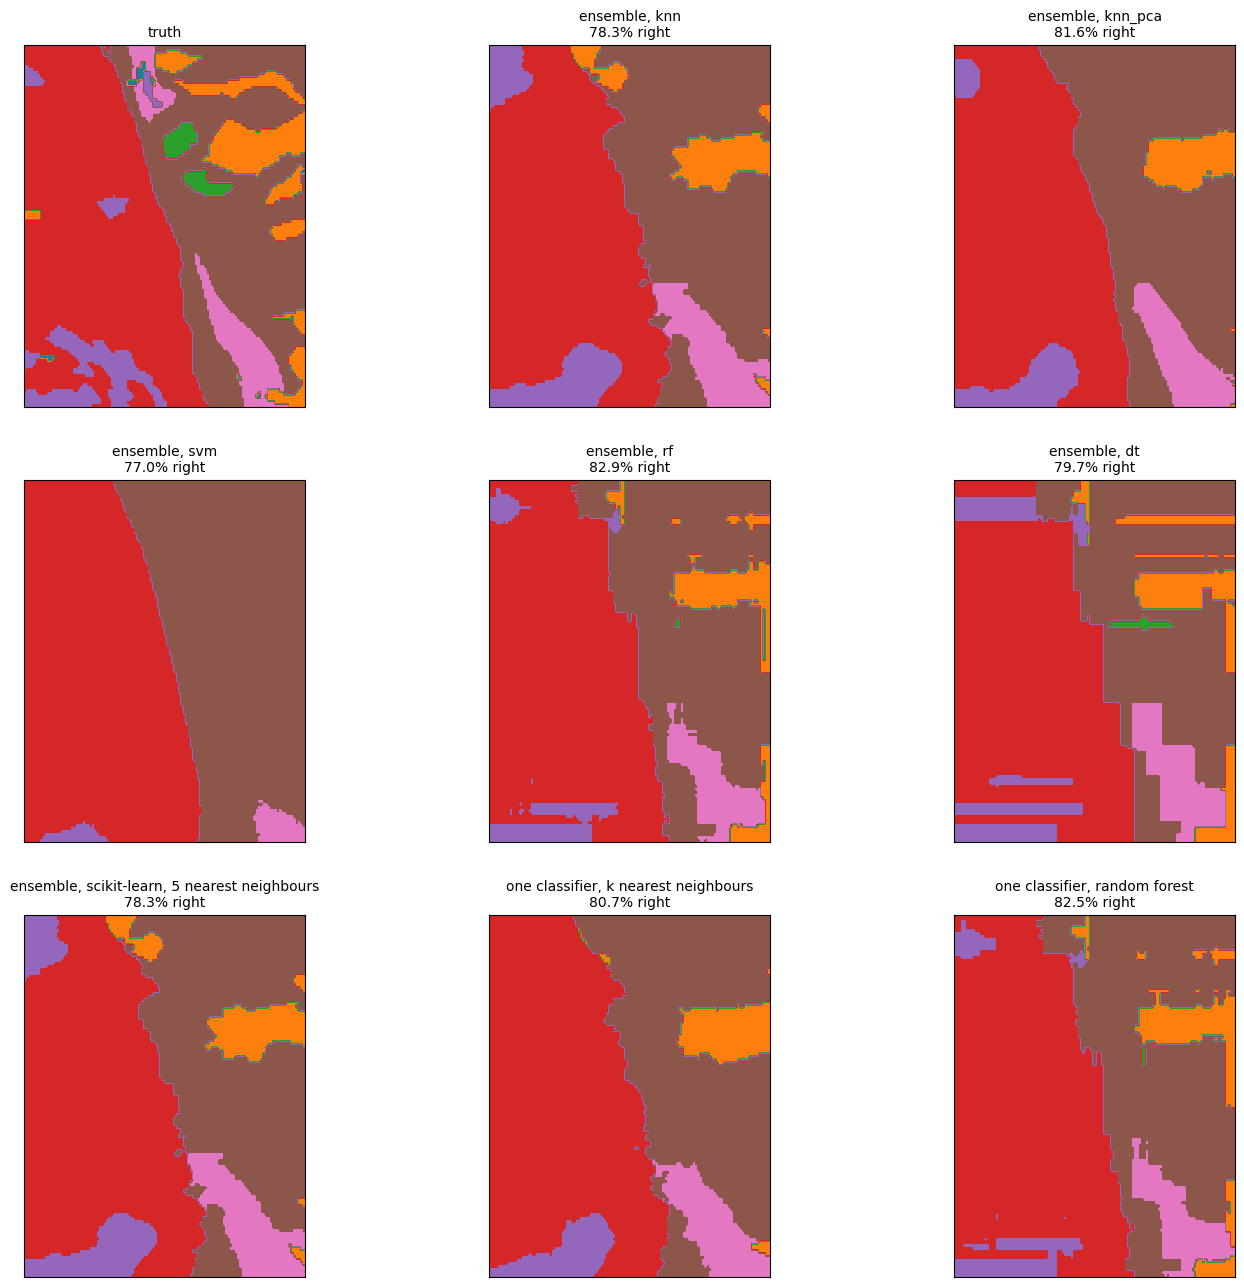

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(17, 16))
panels = [("truth", truth)] + list(estimates.items())
for ax, (title, labels) in zip(axes.ravel(), panels):
    ax.imshow(category_map(labels), origin="lower", extent=extent, cmap=palette,
              vmin=-0.5, vmax=len(lithologies) - 0.5)
    ax.set_title(title if title == "truth" else f"{title}\n{(labels == truth).mean():.1%} right", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

The support-vector machine keeps only the two largest units and the shale in the south-east. The random
forest and the decision tree, in the ensemble as on all the data, draw the units as boxes aligned with
the axes, since a tree splits the plane one coordinate at a time. The nearest-neighbour classifiers draw
rounder units, `knn_pca` with the cleanest contacts. None of them recovers the small units of basalt, a
rock a single sample represents. The share of right cells favours the large units, so the maps with the
highest share, those of the random forests, are not the most faithful to the shapes of the units.

### A limit of categorical data

The theory Spatialize rests on explains why such different maps can fit the same data. It models a field
as a random partition of the domain into blocks, with one value drawn independently in each block. With
continuous values, two places show the same value only if they lie in one block, so the values reveal
the blocks. A category has only a few values, and two separate blocks often draw the same one. Two
places with the same rock type may then share a block or lie in two blocks of that rock, and the
categories cannot say which.

A small experiment shows how far this goes, on tiles of 2 × 2 squares. The four squares of a tile are
grouped into blocks at random, in one of two ways that this theory builds to show the limit. The first sometimes puts all four squares into one block. The second never does, while it puts
pairs and triples of squares together exactly as often as the first. Each block then draws one of two
colours, as a category would. We collect, from each way, tiles whose four squares came out the same
colour, and look at the blocks behind them. In the figure the upper row shows what the categories show
of every one of these tiles, four brown squares, the same in both ways. The two rows below show the
blocks behind twelve such tiles, drawn in the first way and in the second, each block in its own
colour.

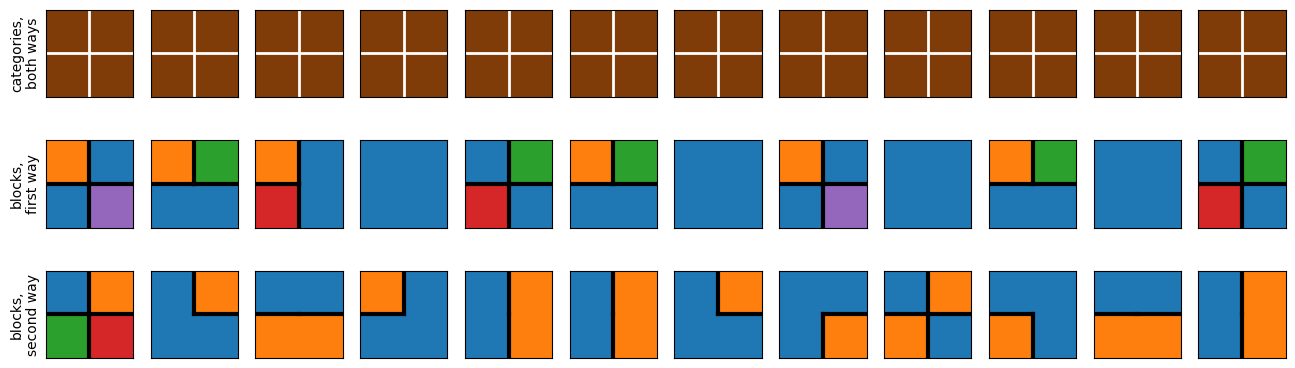

In [6]:
from itertools import combinations

def groupings(law, rng, n_tiles):
    # a grouping of the four squares of each tile, as a block label per square (0 to 4)
    p = 0.3                                                       # the share of the second colour
    mu4 = p ** 2 / (1 - p) + (1 - p) ** 2 / p                     # makes both ways give the same colours
    a, c, d, D = 1 + mu4 / 3, mu4 / 3, 3 + mu4, 7 + 2 * mu4
    if law == "first way":
        options = [[0, 0, 0, 0]] + [[0 if k in pair else k + 1 for k in range(4)] for pair in combinations(range(4), 2)]
        weights = [1] + [a] * 6
    else:
        options = [[0 if k != out else 1 for k in range(4)] for out in range(4)] + [[0, 0, 1, 1], [0, 1, 0, 1], [0, 1, 1, 0]] + [[0, 1, 2, 3]]
        weights = [1] * 4 + [c] * 3 + [d]
    return np.array(options)[rng.choice(len(options), n_tiles, p=np.array(weights) / D)], p

laws, rows = ("first way", "second way"), {}
fig, axes = plt.subplots(3, 12, figsize=(16, 4.8))
for r, law in enumerate(laws):
    rng = np.random.default_rng(1)
    blocks, p = groupings(law, rng, 200_000)
    colours = (rng.random((200_000, 5)) < p)[np.arange(200_000)[:, None], blocks]       # [tile, square]
    one_colour = np.all(colours == colours[:, :1], axis=1)
    rows[law] = {"tiles of one colour": one_colour.mean(), "tiles that are one block": np.mean(np.all(blocks == blocks[:, :1], axis=1))}
    for k, t in enumerate(np.flatnonzero(one_colour & colours[:, 0])[:12]):       # twelve all-brown tiles
        tile_blocks = blocks[t].reshape(2, 2)
        if r == 0:                                                                # what the categories show, alike in both ways
            axes[0, k].imshow(colours[t].reshape(2, 2), cmap=ListedColormap(["#fee0b6", "#7f3b08"]), vmin=0, vmax=1)
            axes[0, k].axhline(0.5, color="white", lw=2); axes[0, k].axvline(0.5, color="white", lw=2)
        ax = axes[r + 1, k]
        ax.imshow(tile_blocks, cmap="tab10", vmin=0, vmax=9)
        for (y, x), (y2, x2) in (((0, 0), (0, 1)), ((1, 0), (1, 1)), ((0, 0), (1, 0)), ((0, 1), (1, 1))):
            if tile_blocks[y, x] != tile_blocks[y2, x2]:                          # a line between different blocks
                if y == y2: ax.plot([0.5, 0.5], [y - 0.5, y + 0.5], color="black", lw=3)
                else: ax.plot([x - 0.5, x + 0.5], [0.5, 0.5], color="black", lw=3)
    axes[r + 1, 0].set_ylabel(f"blocks,\n{law}", fontsize=10)
axes[0, 0].set_ylabel("categories,\nboth ways", fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Every tile in the upper row is all brown, in both ways alike. Behind them the blocks differ. In the first
way four of the twelve tiles are one block, coloured in a single draw. In the second none is, every tile
being two to four blocks, drawn apart, that happened to come out brown together. A block need not be
connected, so two diagonal squares can form one.

The two ways can be compared exactly. Each row of the figure below lists, under its bars, the objects
whose probabilities are compared, drawn as tiles, with a bar for the first way and one for the second. The
upper row lists the fifteen ways of grouping the four squares into blocks. The middle row lists the sets of
squares whose co-occurrence we measure, the probability that they share a block, the six pairs, the four
triples and all four, in magenta. The lower row lists the sixteen patterns of the two colours a tile can
show, in brown and cream, which are what the data record.

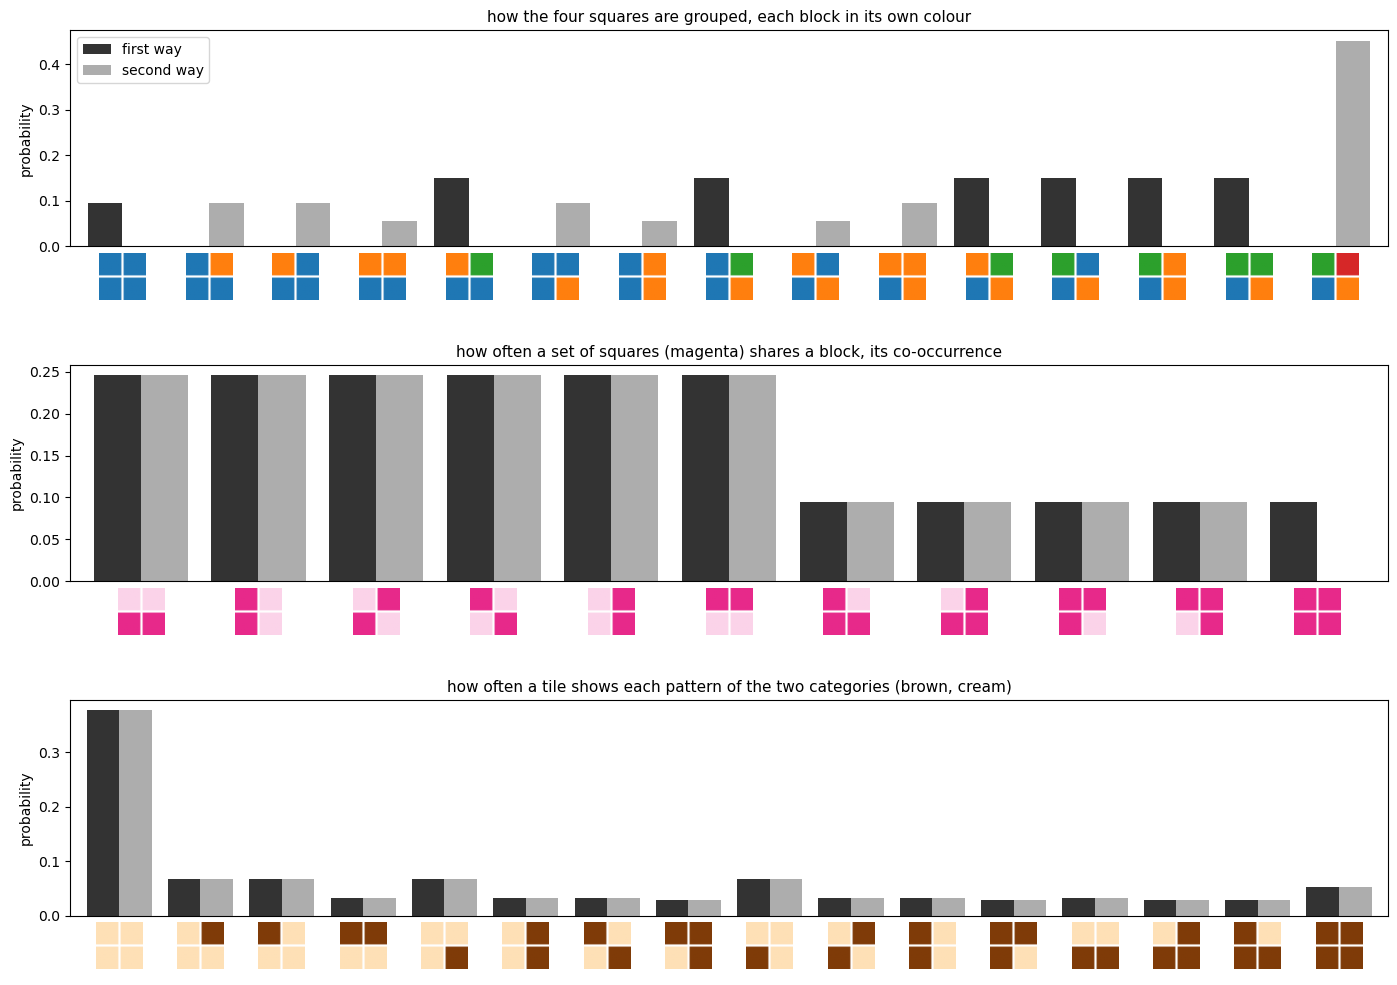

In [7]:
from itertools import product

def canonical(labels):
    # a grouping of the four squares, labelled in order of first appearance
    seen = {}
    return tuple(seen.setdefault(b, len(seen)) for b in labels)

def exact_law(law):
    # the probability of each of the 15 groupings, in each way
    options, weights = {"first way": ([[0, 0, 0, 0]] + [[0 if k in pair else k + 1 for k in range(4)] for pair in combinations(range(4), 2)],
                                      None),
                        "second way": ([[0 if k != out else 1 for k in range(4)] for out in range(4)]
                                       + [[0, 0, 1, 1], [0, 1, 0, 1], [0, 1, 1, 0]] + [[0, 1, 2, 3]], None)}[law]
    p = 0.3
    mu4 = p ** 2 / (1 - p) + (1 - p) ** 2 / p
    a, c, d, D = 1 + mu4 / 3, mu4 / 3, 3 + mu4, 7 + 2 * mu4
    w = [1] + [a] * 6 if law == "first way" else [1] * 4 + [c] * 3 + [d]
    return {canonical(o): wi / D for o, wi in zip(options, w)}, p

every_grouping = sorted({canonical(l) for l in product(range(4), repeat=4)})
subsets = [s for size in (2, 3, 4) for s in combinations(range(4), size)]
patterns = list(product((0, 1), repeat=4))
exact = {}
for law in laws:
    q, p = exact_law(law)
    exact[law] = {
        "grouping": [q.get(g, 0.0) for g in every_grouping],
        "together": [sum(w for g, w in q.items() if len({g[k] for k in s}) == 1) for s in subsets],
        "colours": [sum(w * np.prod([(p if pattern[[k for k in range(4) if g[k] == b][0]] else 1 - p)
                                     if len({pattern[k] for k in range(4) if g[k] == b}) == 1 else 0.0
                                     for b in set(g)]) for g, w in q.items()) for pattern in patterns]}

from matplotlib.colors import to_rgb
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

def icon(colours):
    # a 2 x 2 tile as a small image, its four squares parted by white lines
    image = np.ones((21, 21, 3))
    for k, colour in enumerate(colours):
        y, x = divmod(k, 2)
        image[11 * (1 - y): 11 * (1 - y) + 10, 11 * x: 11 * x + 10] = to_rgb(colour)
    return image

tab = plt.cm.tab10.colors
icons = {"grouping": [icon([tab[b] for b in g]) for g in every_grouping],
         "together": [icon(["#e7298a" if k in s else "#fbd3e9" for k in range(4)]) for s in subsets],
         "colours": [icon(["#7f3b08" if c else "#fee0b6" for c in pattern]) for pattern in patterns]}
titles = {"grouping": "how the four squares are grouped, each block in its own colour",
          "together": "how often a set of squares (magenta) shares a block, its co-occurrence",
          "colours": "how often a tile shows each pattern of the two categories (brown, cream)"}
fig, axes = plt.subplots(3, 1, figsize=(17, 11.5))
for ax, key in zip(axes, ("grouping", "together", "colours")):
    first, second = np.array(exact["first way"][key]), np.array(exact["second way"][key])
    x = np.arange(len(first))
    ax.bar(x - 0.2, first, 0.4, color="0.2", label="first way")
    ax.bar(x + 0.2, second, 0.4, color="0.68", label="second way")
    for k in x:
        ax.add_artist(AnnotationBbox(OffsetImage(icons[key][k], zoom=1.6), (k, 0), xycoords=("data", "axes fraction"),
                                     box_alignment=(0.5, 1.15), frameon=False))
    ax.set_xticks([]); ax.set_xlim(-0.6, len(first) - 0.4); ax.set_ylabel("probability")
    ax.set_title(titles[key], fontsize=11)
axes[0].legend()
fig.subplots_adjust(hspace=0.55)
plt.show()

In the upper row each grouping has a bar in one way only, the other way never using it. The two ways are
two different scenarios. In the middle row, the bars of every pair and of every triple are equal, the two
ways joining them equally often. Only the last set, all four squares, parts them, joined 9 % of the time in
the first way and never in the second. In the lower row, the two bars of every pattern of colours are
equal. The data, the colours, come out with exactly the same probabilities in both scenarios,
so no amount of them tells the two apart, and with them how often four squares belong together. The
theory Spatialize rests on proves that this holds in general. Two categories fix how often pairs and
triples of places share a block, never how often four or more do. The documentation's
[Categorical variables](https://spatialize.readthedocs.io/en/latest/theory/categorical.html) and
[The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html) give the
model and the result.

For estimation, this means that categorical data cannot fix the shapes of the units beyond pairs and
triples of locations. The partitions and the classifier supply that structure, which is why the eight maps
of the same data above differ in the shapes of their units while fitting the data about equally well. The
disagreement among the members measures that freedom location by location.

### The probability of each category

`class_probabilities()` returns, at each location, the share of members naming each category. The vote
takes the largest. The shares say how much the other categories weigh.

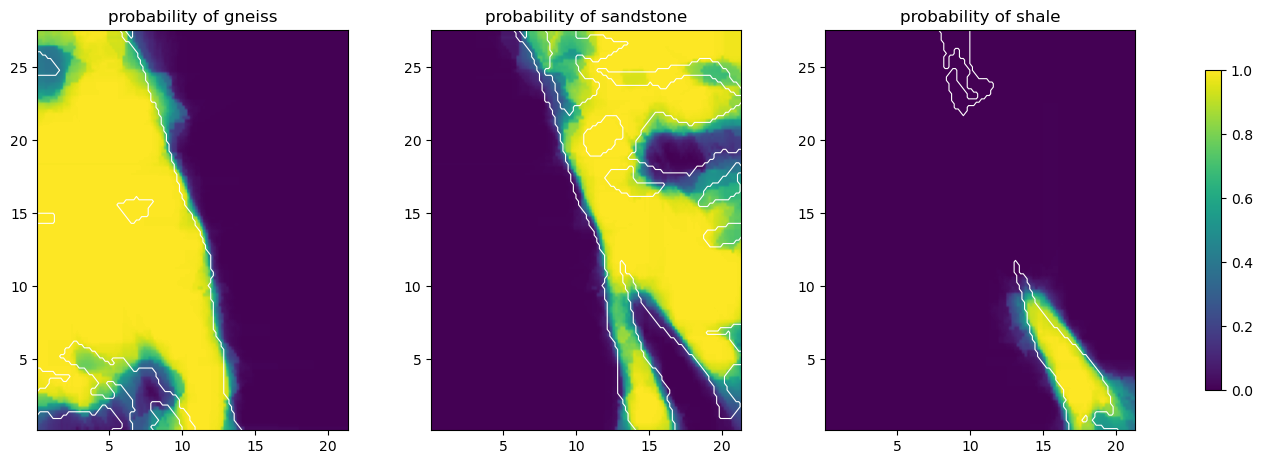

In [7]:
categories, probabilities = result.class_probabilities()
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, name in zip(axes, ["gneiss", "sandstone", "shale"]):
    im = ax.imshow(probabilities[:, categories.index(name)].reshape(shape), origin="lower", extent=extent,
                   cmap="viridis", vmin=0, vmax=1)
    ax.contour(np.linspace(extent[0], extent[1], 120), np.linspace(extent[2], extent[3], 120),
               (truth == name).reshape(shape).astype(float), levels=[0.5], colors="white", linewidths=0.8)
    ax.set_title(f"probability of {name}")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

The white line bounds each lithology in the truth. Inside a large unit its probability is close to one.
It falls across the contacts, where members from partitions cut on either side name different units.

### The disagreement as a warning

The disagreement, the share of members that differ from the vote (`precision()`), is the ensemble's own
measure of doubt. Splitting the map by its disagreement shows how well that doubt points at the errors.

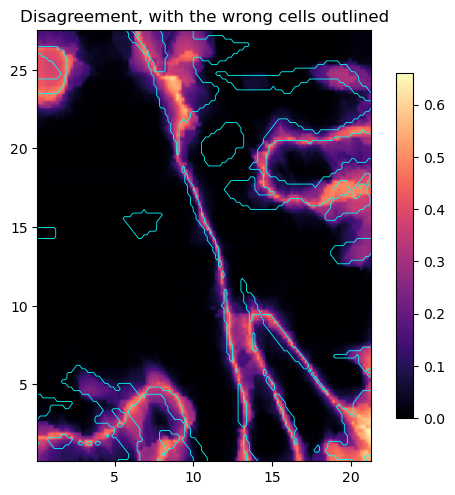

,cells,share wrong
band,,
none,5801,0.054
up to 0.1,4567,0.112
0.1 to 0.3,2460,0.362
above 0.3,1572,0.588


In [8]:
disagreement = result.precision()
bands = pd.cut(disagreement, [-0.001, 0.0, 0.1, 0.3, 1.0], labels=["none", "up to 0.1", "0.1 to 0.3", "above 0.3"])
by_band = pd.DataFrame({"band": bands, "wrong": wrong}).groupby("band", observed=True)["wrong"].agg(["size", "mean"])
by_band.columns = ["cells", "share wrong"]

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(disagreement.reshape(shape), origin="lower", extent=extent, cmap="magma")
ax.contour(np.linspace(extent[0], extent[1], 120), np.linspace(extent[2], extent[3], 120),
           wrong.reshape(shape).astype(float), levels=[0.5], colors="cyan", linewidths=0.6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Disagreement, with the wrong cells outlined")
plt.show()
by_band.round(3)

Among the cells where all the members agree, 5 % are wrong. Above a disagreement of 0.3, 59 % are. The
disagreement rises along the contacts, where most errors lie. It misses errors of another kind, the
small units no sample reached, such as the unit around x = 11, y = 20, where every member names the
surrounding unit. An ensemble can doubt only between categories its data hold nearby.

### An ordered variable

The geological eras are ordered, Cenozoic the youngest, Proterozoic the oldest. With
`set_ordinal_order`, `re_estimate("mv")` takes the median of the members along that order instead of
their mode, so a split between two eras cannot settle on an era outside them. A few cells of the map
belong to no era and are left out.

In [9]:
order = {"Cenozoic": 0, "Mesozoic": 1, "Paleozoic": 2, "Proterozoic": 3}
has_era = samples["era"].values != ""
eras = cat_esi_nongriddata(points[has_era], samples["era"].values[has_era], xi, classifier="knn_pca",
                           n_partitions=200, alpha=best["alpha"], seed=0)
nominal = eras.estimation().copy()
ordinal = eras.set_ordinal_order(order).re_estimate("mv")
true_era = grid["era"].values
known = true_era != ""

def rank(labels):
    return np.array([order[c] for c in labels])

pd.DataFrame({name: {"share right": (e[known] == true_era[known]).mean(),
                     "mean distance in eras": np.abs(rank(e[known]) - rank(true_era[known])).mean(),
                     "share off by two eras or more": (np.abs(rank(e[known]) - rank(true_era[known])) > 1).mean()}
              for name, e in (("mode, nominal", nominal), ("median, ordinal", ordinal))}).T.round(4)

,share right,mean distance in eras,share off by two eras or more
"mode, nominal",0.8804,0.1285,0.0075
"median, ordinal",0.8823,0.1265,0.0072


The median gets the era right on 88.2 % of the map against 88.0 % for the mode, the mean distance in eras moving by a few thousandths. Splits between eras two apart are rare on this map, so the order changes
little. It matters where the members of a location divide between distant categories.

### An amount within categories

An amount often depends on the category that holds it, a soil nutrient on the soil type, a price on the
zoning class, the copper content of a rock on its rock type. The last example is our data, 400 samples
of an Andean copper deposit, each with a rock type and a copper content. We can estimate the amount from
all the samples, or within each category from its own samples only, a common practice wherever the
categories are known to differ. The leave-one-out error of the Pareto search, at its knee, compares the two.

In [10]:
andes, _, _, _ = load_drill_holes_andes_2D()
xy, copper, rocktype = andes[["x", "y"]].values, andes["cu"].values, andes["rocktype"].values
print(andes.groupby("rocktype")["cu"].agg(["count", "mean", "std"]).round(3).T)

search_kw = dict(local_interpolator="adaptiveidw", n_partitions=[100], alpha=[0.7, 0.8, 0.9, 0.95], k="loo",
                 scoring=sf.mae, seed=0)
all_samples = esi_pareto_hparams_search(xy, copper, **search_kw).best_result(strategy="knee")["decoder_error"]
within, counted = 0.0, 0
for code_ in np.unique(rocktype):
    mask = rocktype == code_
    if mask.sum() < 20:
        continue                                    # too few samples for a search of their own
    within += esi_pareto_hparams_search(xy[mask], copper[mask], **search_kw).best_result(strategy="knee")["decoder_error"] * mask.sum()
    counted += mask.sum()
print(f"leave-one-out error, all samples {all_samples:.3f}, within rock types {within / counted:.3f} "
      f"({counted} samples in rock types with 20 or more)")

rocktype       4        20      28      29      31     34
count     112.000  210.000  25.000  12.000  32.000  9.000
mean        0.668    1.246   0.509   0.603   0.948  1.089
std         0.369    0.558   0.186   0.084   0.467  0.437
leave-one-out error, all samples 0.097, within rock types 0.107 (379 samples in rock types with 20 or more)


Rock type 20 carries almost twice the copper of rock type 4, so splitting by rock type looks natural.
Yet the leave-one-out error grows from 0.097 to 0.107 when each rock type is estimated from its own
samples alone. Each estimate then draws on fewer samples, which here weighs more than the difference
between the rock types. Splitting is a choice to check by cross-validation, not a rule.

### Categories in three dimensions

Samples along the boreholes of the same deposit give 2 376 points in three dimensions, each with a rock
type, as a soil profile gives horizons at depth or an aquifer survey gives layers. Categorical ESI works in
three dimensions as in two, the cells of the partitions being boxes. We estimate the rock type on the
72 529 blocks of the deposit's model and draw one horizontal level.

92 s for 72529 blocks


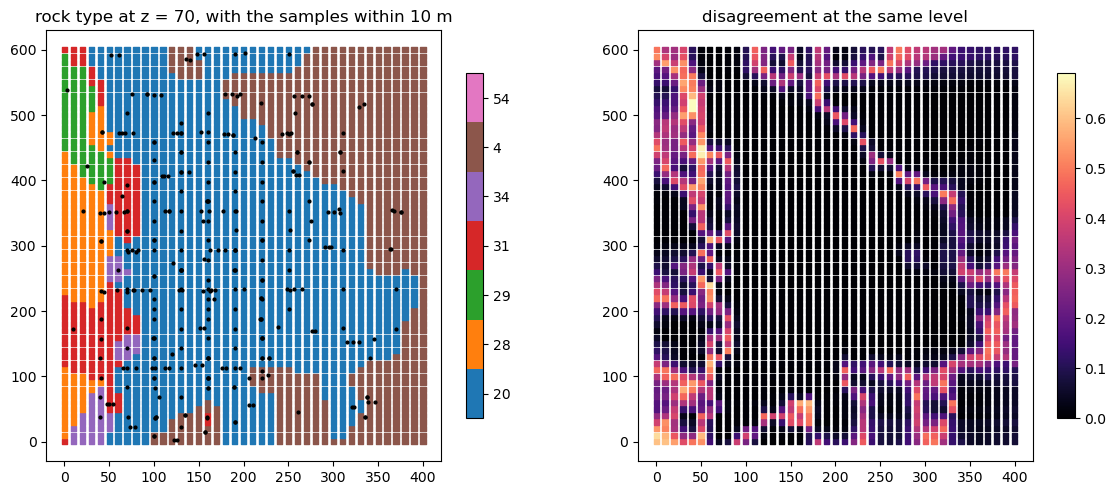

In [11]:
holes, blocks = load_drill_holes_andes_3D()
start = time.perf_counter()
rocks3d = cat_esi_nongriddata(holes[["x", "y", "z"]].values, holes["rocktype"].astype(int).astype(str).values,
                              blocks[["x", "y", "z"]].values, classifier="knn_pca", n_partitions=100,
                              alpha=0.8, seed=0)
print(f"{time.perf_counter() - start:.0f} s for {len(blocks)} blocks")

level = blocks["z"].values == np.median(np.unique(blocks["z"]))
types3d = sorted(set(rocks3d.estimation()))
codes = np.array([types3d.index(c) for c in rocks3d.estimation()])
near = np.abs(holes["z"].values - blocks["z"].values[level][0]) < 10
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
sc = axes[0].scatter(blocks["x"].values[level], blocks["y"].values[level], c=codes[level], s=14, marker="s",
                     cmap=ListedColormap(plt.cm.tab10.colors[:len(types3d)]), vmin=-0.5, vmax=len(types3d) - 0.5)
axes[0].scatter(holes["x"].values[near], holes["y"].values[near], s=4, c="black")
axes[0].set_title(f"rock type at z = {blocks['z'].values[level][0]:.0f}, with the samples within 10 m")
cbar = fig.colorbar(sc, ax=axes[0], ticks=range(len(types3d)), shrink=0.8)
cbar.ax.set_yticklabels(types3d)
dis3d = rocks3d.precision()
im = axes[1].scatter(blocks["x"].values[level], blocks["y"].values[level], c=dis3d[level], s=14, marker="s", cmap="magma")
axes[1].set_title("disagreement at the same level")
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.show()

The level shows broad zones, rock type 20 in the centre and rock type 4 around it, with smaller types
along the western edge. The disagreement follows the contacts between them, as on the 2D map, and is
highest on the western edge, where several small rock types meet.

## Pitfalls

- **Rare categories.** A category with one or two samples can only be estimated near them. Its share of
  the map, and of the vote, says nothing reliable.
- **Accuracy as the only judge.** Several classifiers reach the same share of right cells. The ensemble adds the likely places of the errors, read from the disagreement.
- **The vote's probabilities taken at face value.** The shares of the members come from partitions that
  share the data, so they are not independent opinions. Read them as relative support, and check them
  where a truth exists, as here.
- **Splitting by category without checking.** Estimating an amount within each category leaves each
  estimate fewer data. Compare both routes by cross-validation before choosing.

## Try it yourself

1. Draw 600 samples of the Golden map (`load_lithology_golden(n_samples=600)`) and watch the errors on the
   contacts.
2. Estimate the era with each classifier and compare the median vote with the mode.
3. Use Voronoi partitions (`p_process="voronoi"`) and compare the disagreement along the contacts.
4. Give a classifier of your own through `classifier="scikit-learn"`.

## Next

- *Aggregating categorical ensembles*, for the vote, its weighted form and Dawid–Skene, with every
  classifier.
- *The decoders*, for the continuous counterpart of the classifiers.
- *Cells without data*, for what `empty_cells` gives a categorical member.
- The documentation's [Categorical estimation](https://spatialize.readthedocs.io/en/latest/theory/categorical.html)
  (theory) and [categorical ESI reference](https://spatialize.readthedocs.io/en/latest/reference/cat_esi.html).